# ДЗ по сингл селлу 1


In [1]:
import os
import tarfile
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
import scanpy as sc

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, facecolor='white', frameon=False)

---
# Часть 1. Клеточный цикл и PCA на данных PBMC 3k

In [2]:
# Загрузка PBMC 3k (из локального кэша/папки или из коллекции Scanpy)
cache_pbmc = Path("data/pbmc3k_after_pca.h5ad")
raw_folder_pbmc = Path("data/filtered_gene_bc_matrices/hg19")

if cache_pbmc.exists():
    adata_pbmc = sc.read_h5ad(cache_pbmc)
else:
    if raw_folder_pbmc.exists():
        adata_pbmc = sc.read_10x_mtx(raw_folder_pbmc, var_names="gene_symbols", make_unique=True)
    else:
        adata_pbmc = sc.datasets.pbmc3k()

    # Стандартный пайплайн QC, HVG и PCA из Семинара 1
    adata_pbmc.var["mt"] = adata_pbmc.var_names.str.startswith("MT-")
    sc.pp.calculate_qc_metrics(adata_pbmc, qc_vars=["mt"], inplace=True)
    sc.pp.filter_cells(adata_pbmc, min_genes=200)
    sc.pp.filter_genes(adata_pbmc, min_cells=3)
    adata_pbmc = adata_pbmc[
        (adata_pbmc.obs["n_genes_by_counts"] < 2500) &
        (adata_pbmc.obs["pct_counts_mt"] < 5)
    ].copy()

    adata_pbmc.layers["counts"] = adata_pbmc.X.copy()
    sc.pp.highly_variable_genes(adata_pbmc, layer="counts", flavor="seurat_v3", n_top_genes=2000)
    sc.pp.normalize_total(adata_pbmc, target_sum=1e4)
    sc.pp.log1p(adata_pbmc)
    sc.tl.pca(adata_pbmc, n_comps=50, mask_var="highly_variable", random_state=42)

print(adata_pbmc)

try downloading from url
https://falexwolf.de/data/pbmc3k_raw.h5ad
... this may take a while but only happens once


/home/khokholmongolll/miniconda3/envs/sc_pbmc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 5.58M/5.58M [00:12<00:00, 474kB/s] 


filtered out 19024 genes that are detected in less than 3 cells
extracting highly variable genes
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:01)
AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'


Найдено генов в PBMC 3k — S-фаза: 36, G2/M-фаза: 44


/home/khokholmongolll/miniconda3/envs/sc_pbmc/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


calculating cell cycle phase
computing score 'S_score'
    finished (0:00:00)
computing score 'G2M_score'
    finished (0:00:00)

Распределение клеток PBMC 3k по фазам клеточного цикла:
phase
G1     1037
S       812
G2M     789
Name: count, dtype: int64


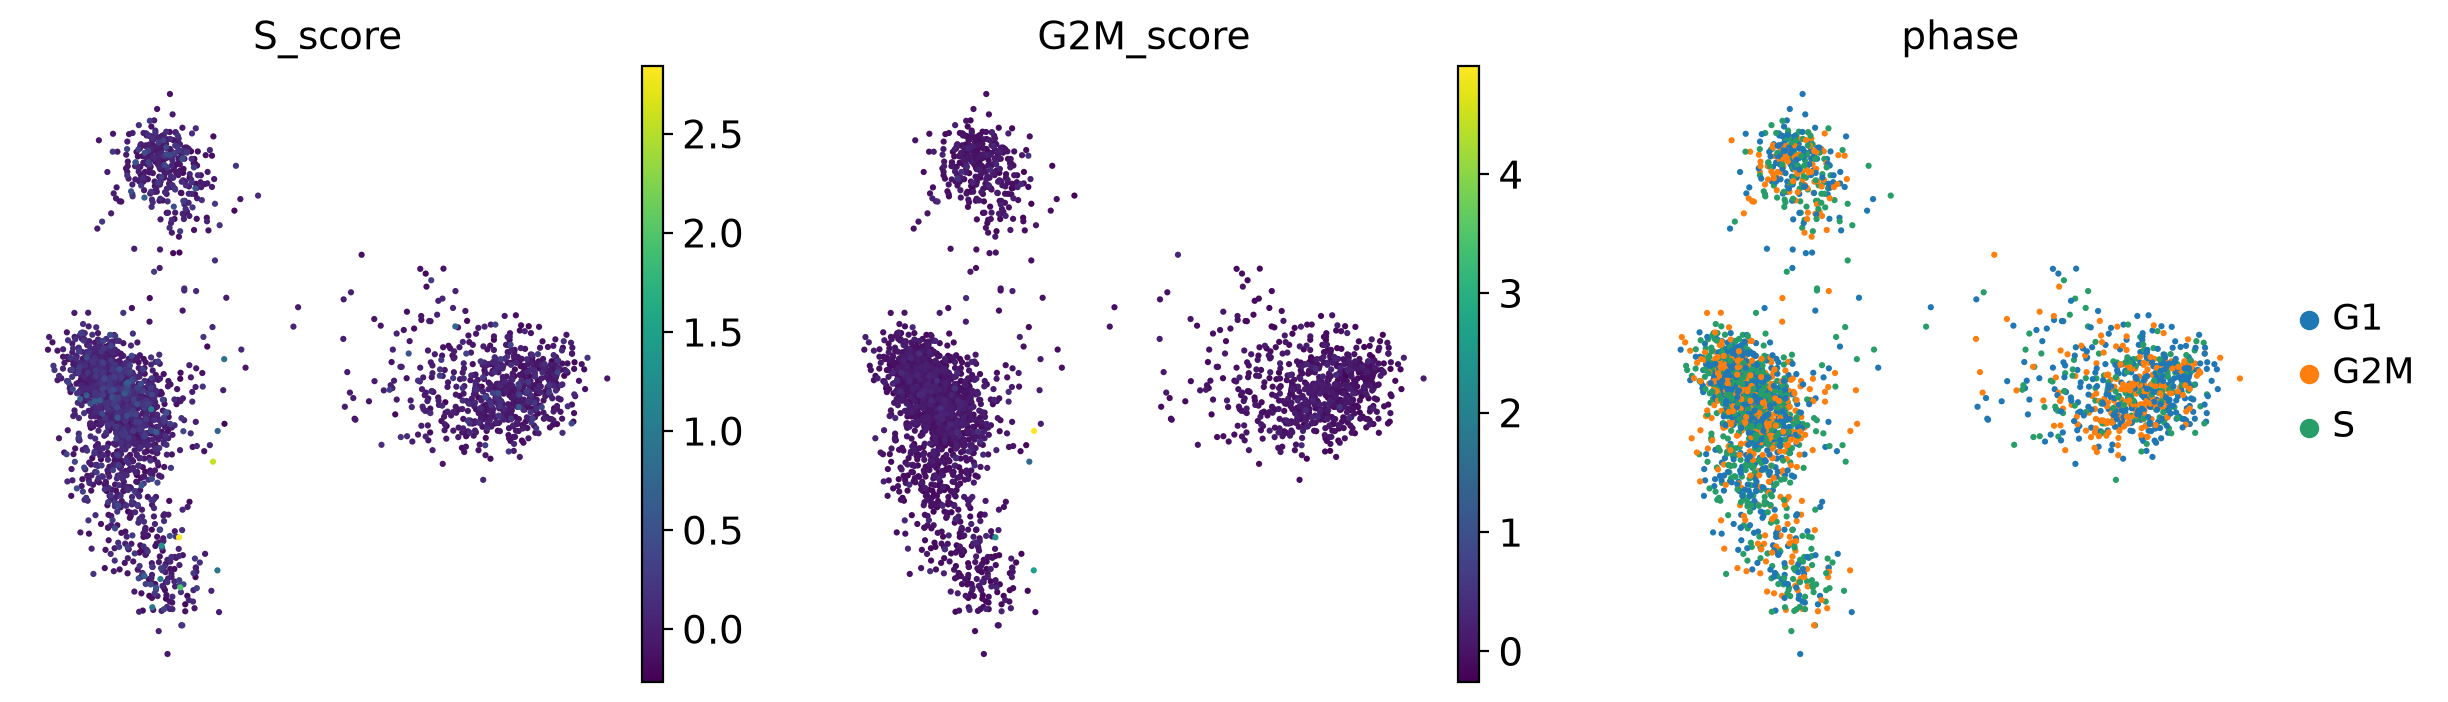

In [3]:
# Канонические списки генов клеточного цикла человека (Tirosh et al., 2016)
s_genes = [
    'MCM5', 'PCNA', 'TYMS', 'FEN1', 'MCM2', 'MCM4', 'RRM1', 'UNG', 'GINS2', 'MCM6',
    'CDCA7', 'DTL', 'PRIM1', 'UHRF1', 'MLF1IP', 'HELLS', 'RFC2', 'RPA2', 'NASP', 'RAD51AP1',
    'GMNN', 'WDR76', 'SLBP', 'CCNE2', 'UBR7', 'POLD3', 'MSH2', 'ATAD2', 'RAD51', 'RRM2',
    'CDC45', 'CDC6', 'EXO1', 'TIPIN', 'DSCC1', 'BLM', 'CASP8AP2', 'USP1', 'CLSPN', 'POLA1',
    'CHAF1B', 'BRIP1', 'E2F8'
]

g2m_genes = [
    'HMGB2', 'CDK1', 'NUSAP1', 'UBE2C', 'BIRC5', 'TPX2', 'TOP2A', 'NDC80', 'CKS2', 'NUF2',
    'CKS1B', 'MKI67', 'TMPO', 'CENPF', 'TACC3', 'FAM64A', 'SMC4', 'CCNB2', 'CKAP2L', 'CKAP2',
    'AURKB', 'BUB1', 'KIF11', 'ANP32E', 'TUBB4B', 'GTSE1', 'KIF20B', 'HJURP', 'CDCA3', 'HN1',
    'CDC20', 'TTK', 'CDC25C', 'KIF2C', 'RANGAP1', 'NCAPD2', 'DLGAP5', 'CDCA2', 'CDCA8', 'ECT2',
    'KIF23', 'HMMR', 'AURKA', 'PSRC1', 'ANLN', 'LBR', 'CKAP5', 'CENPE', 'CTCF', 'NEK2',
    'G2E3', 'GAS2L3', 'CBX5', 'CENPA'
]

s_genes_pbmc = [g for g in s_genes if g in adata_pbmc.var_names]
g2m_genes_pbmc = [g for g in g2m_genes if g in adata_pbmc.var_names]
print(f"Найдено генов в PBMC 3k — S-фаза: {len(s_genes_pbmc)}, G2/M-фаза: {len(g2m_genes_pbmc)}")

# Расчёт score_genes_cell_cycle на стандартизованной копии
ad_pbmc_cc = adata_pbmc.copy()
sc.pp.scale(ad_pbmc_cc, max_value=10)
sc.tl.score_genes_cell_cycle(ad_pbmc_cc, s_genes=s_genes_pbmc, g2m_genes=g2m_genes_pbmc)

for col in ["S_score", "G2M_score", "phase"]:
    adata_pbmc.obs[col] = ad_pbmc_cc.obs[col]

print("\nРаспределение клеток PBMC 3k по фазам клеточного цикла:")
print(adata_pbmc.obs["phase"].value_counts())

sc.pl.pca(adata_pbmc, color=["S_score", "G2M_score", "phase"], ncols=3, size=20, show=True)

### Выводы по клеточному циклу (PBMC 3k):
- **Разделяются ли клетки по фазам клеточного цикла \?**
   **не разделяются**
- **Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?**
   клетки одного типа в пролиферирующей  популяции находятся в разных фазах асинхронного деления

---
# Часть 2. Анализ scRNA-seq данных хрящевой ткани человека (GSE255460)

**GSE255460**, *Fan Y. et al., Ann Rheum Dis, 2024.

Выполним  QC, HVG, PCA, kNN, графовую кластеризацию **Leiden** и **UMAP** с биологической аннотацией субпопуляций хондроцитов.

## 2.1. Загрузка

In [4]:
DATA_DIR = Path("data_gse255460")
SAMPLE_DIR = DATA_DIR / "sample_C1"
DATA_DIR.mkdir(exist_ok=True)
SAMPLE_DIR.mkdir(exist_ok=True)

RAW_TAR_URL = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE255460&format=file"
META_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE255nnn/GSE255460/suppl/GSE255460_metadata.csv.gz"

meta_path = DATA_DIR / "GSE255460_metadata.csv.gz"
raw_tar_path = DATA_DIR / "GSE255460_RAW.tar"

if not meta_path.exists():
    print("Скачивание метаданных GSE255460_metadata.csv.gz...")
    !curl -fL "{META_URL}" -o "{meta_path}"

if not raw_tar_path.exists() and not any(SAMPLE_DIR.iterdir()):
    print("Скачивание GSE255460_RAW.tar (1.0 ГБ)...")
    !curl -fL "{RAW_TAR_URL}" -o "{raw_tar_path}"

def prepare_10x_sample(tar_path: Path, out_dir: Path, sample_prefix: str = "GSM8072834"):
    if (out_dir / "matrix.mtx.gz").exists() or (out_dir / "matrix.mtx").exists():
        print(f"Файлы 10x уже готовы в {out_dir}")
        return
    if not tar_path.exists():
        raise FileNotFoundError(f"Файл {tar_path} не найден. Скачайте GSE255460_RAW.tar в папку {DATA_DIR}")

    print(f"Извлечение файлов для {sample_prefix} из {tar_path}...")
    with tarfile.open(tar_path, "r") as tar:
        members = [m for m in tar.getmembers() if sample_prefix in m.name]
        tar.extractall(path=out_dir, members=members)

    for fpath in out_dir.glob(f"*{sample_prefix}*"):
        fname = fpath.name
        if fname.endswith(".tar.gz") or fname.endswith(".tgz"):
            with tarfile.open(fpath, "r:gz") as subtar:
                subtar.extractall(path=out_dir)
            fpath.unlink()
        elif "matrix.mtx" in fname:
            ext = ".gz" if fname.endswith(".gz") else ""
            fpath.rename(out_dir / f"matrix.mtx{ext}")
        elif "barcodes.tsv" in fname:
            ext = ".gz" if fname.endswith(".gz") else ""
            fpath.rename(out_dir / f"barcodes.tsv{ext}")
        elif "features.tsv" in fname or "genes.tsv" in fname:
            ext = ".gz" if fname.endswith(".gz") else ""
            fpath.rename(out_dir / f"features.tsv{ext}")

    for subfile in out_dir.rglob("*"):
        if subfile.is_file() and subfile.parent != out_dir:
            shutil.move(str(subfile), str(out_dir / subfile.name))

prepare_10x_sample(raw_tar_path, SAMPLE_DIR, sample_prefix="GSM8072834")

adata = sc.read_10x_mtx(
    SAMPLE_DIR,
    var_names="gene_symbols",
    make_unique=True,
    cache=True
)
print(adata)

Файлы 10x уже готовы в data_gse255460/sample_C1
... reading from cache file cache/data_gse255460-sample_C1-matrix.h5ad
AnnData object with n_obs × n_vars = 1573 × 36601
    var: 'gene_ids', 'feature_types'


## 2.2. Контроль качества (QC), отбор HVG, нормализация и PCA

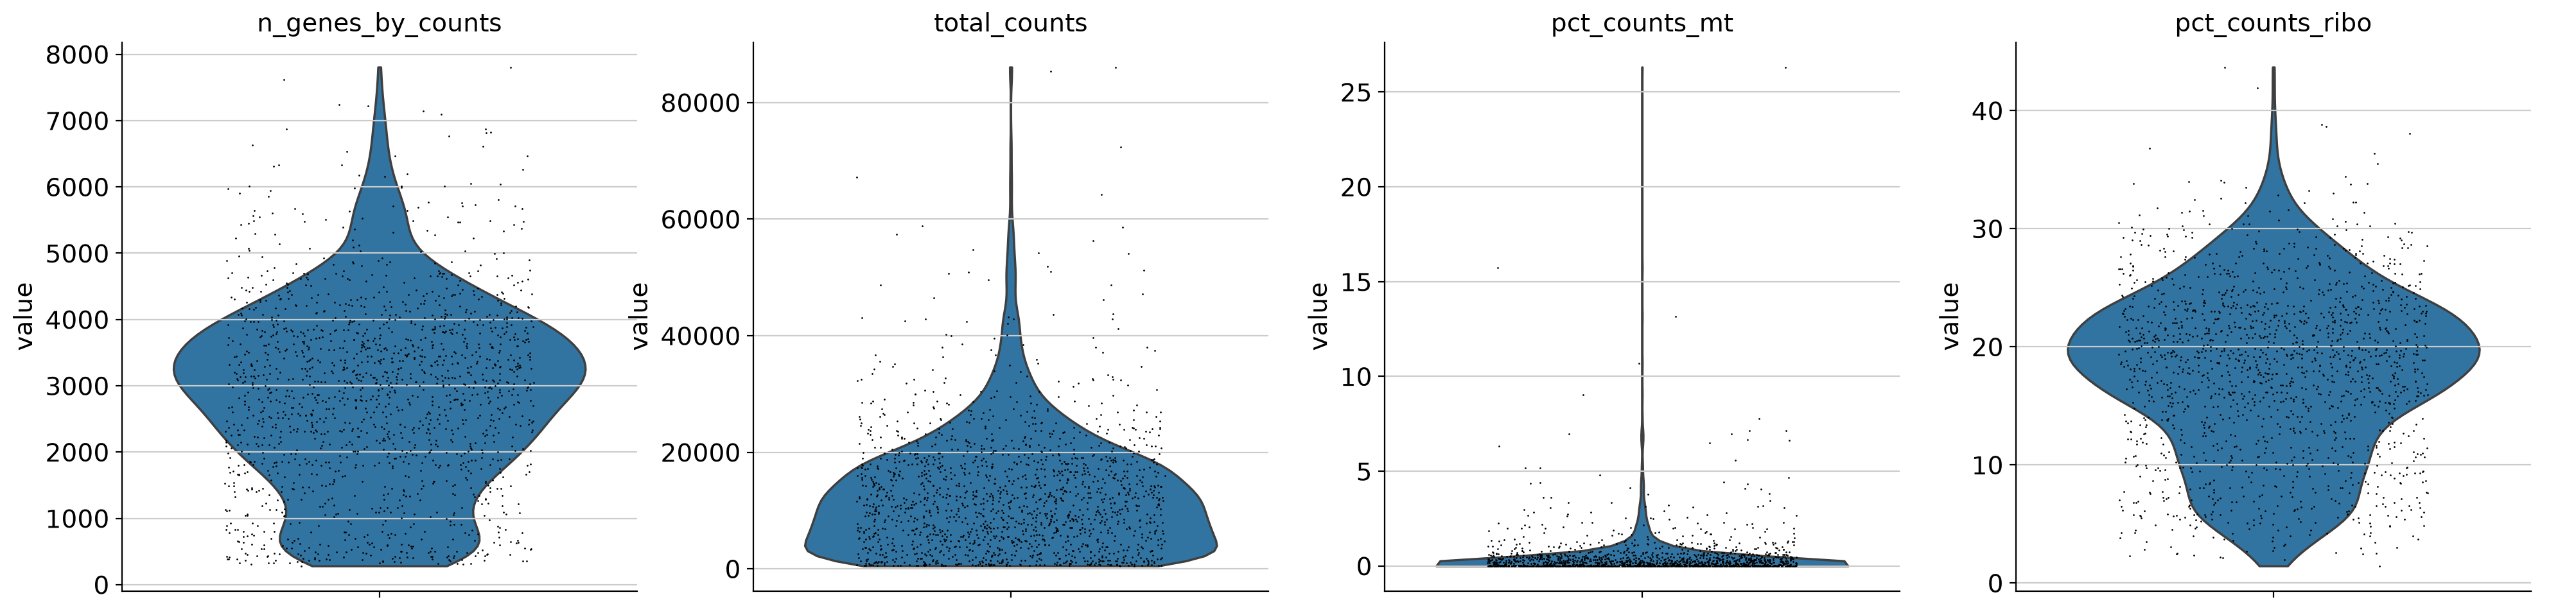

Клеток до фильтрации: 1573, генов: 36601
filtered out 16673 genes that are detected in less than 3 cells
Клеток после фильтрации: 1485, генов: 19928


In [5]:
# Разметка групп генов для QC
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]", regex=True)

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt", "ribo", "hb"],
    percent_top=None,
    log1p=True,
    inplace=True
)

sc.pl.violin(
    adata,
    keys=["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"],
    jitter=0.3,
    multi_panel=True,
    show=True
)

print(f"Клеток до фильтрации: {adata.n_obs}, генов: {adata.n_vars}")
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 5000) &
    (adata.obs["pct_counts_mt"] < 15) &
    (adata.obs["pct_counts_hb"] < 1.0)
].copy()

adata.layers["counts"] = adata.X.copy()
print(f"Клеток после фильтрации: {adata.n_obs}, генов: {adata.n_vars}")

extracting highly variable genes
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:00)


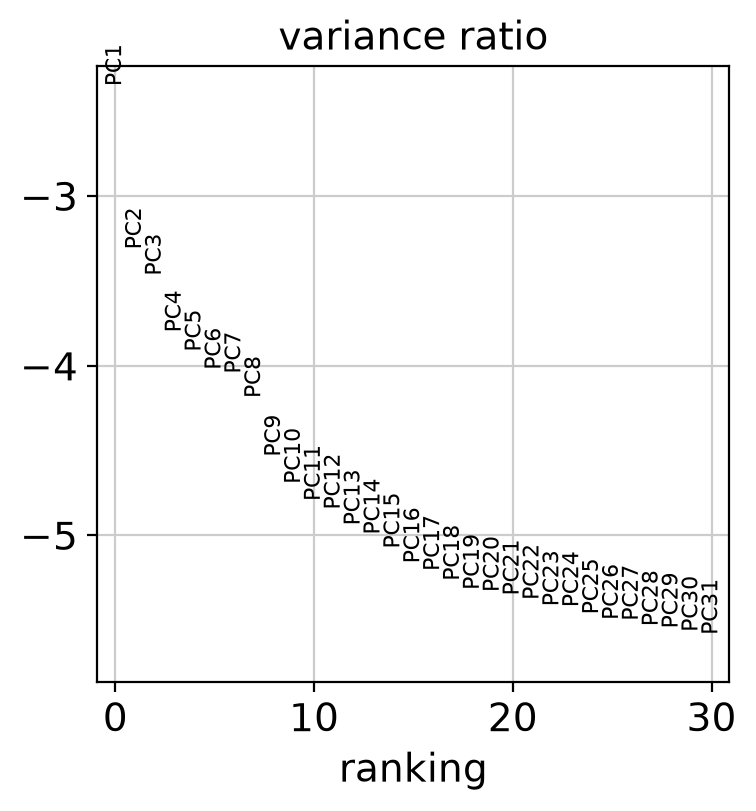

In [6]:
# Отбор 2000 HVG, нормализация и расчёт PCA
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True, show=True)

## 2.3. kNN, кластеризация Leiden и UMAP

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:12)
Граф connectivities: (1485, 1485) ненулевых элементов: 31360
Матрица distances: (1485, 1485) ненулевых элементов: 20790


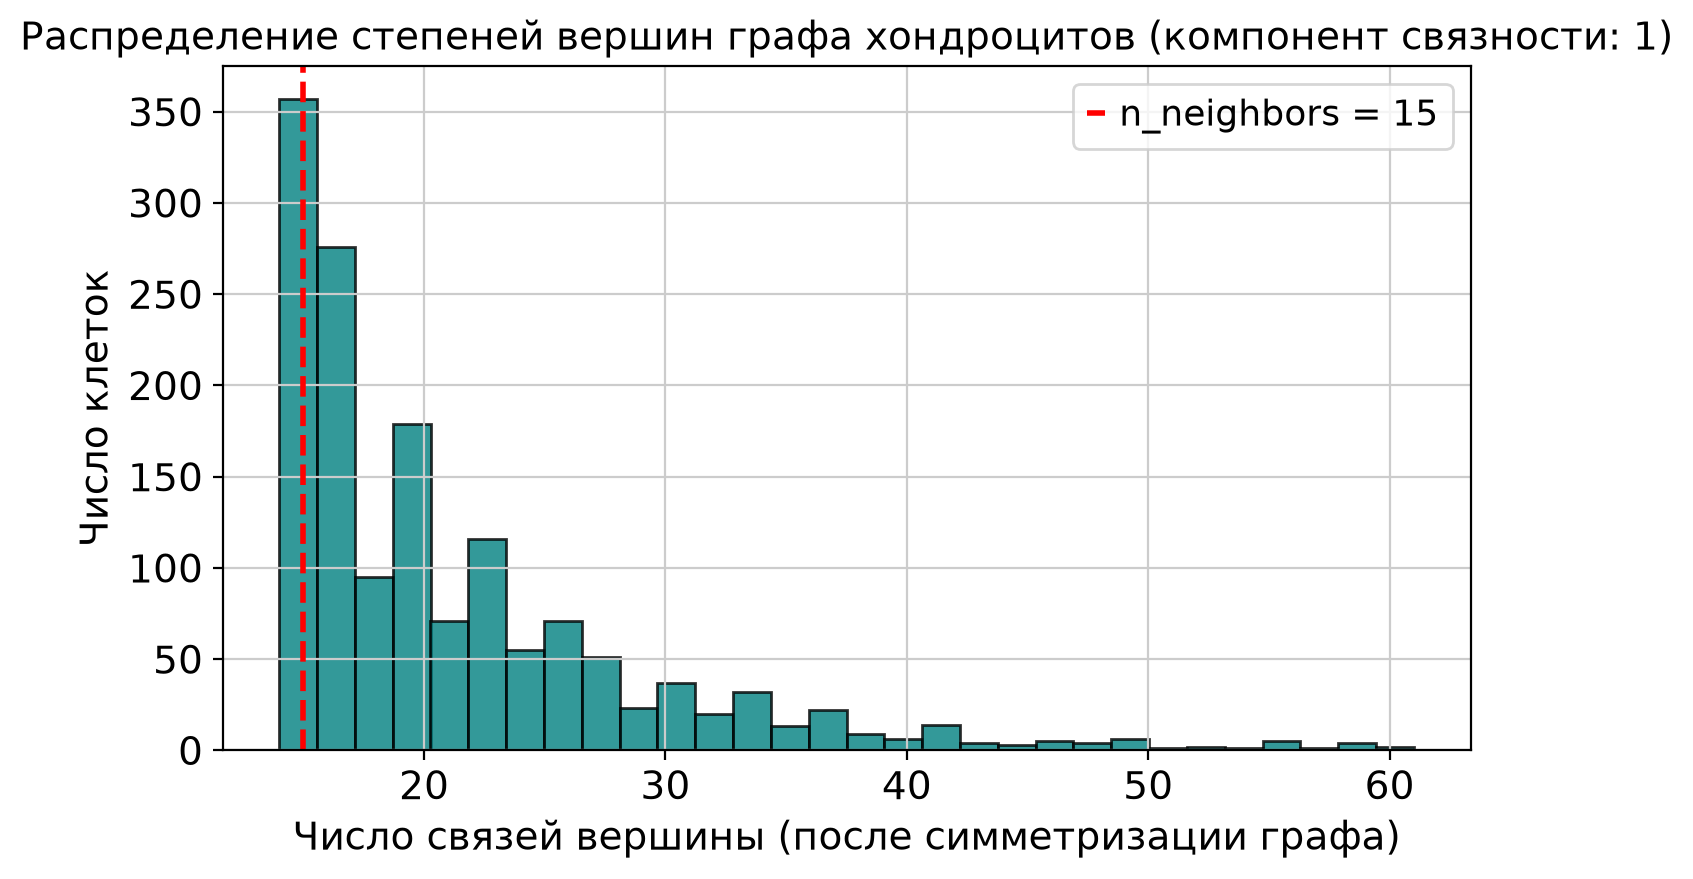

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 / 19.0 / 61


In [7]:
# 1. Построение графа ближайших соседей (kNN) по первым 30 PC
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42
)

G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)
print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

# Анализ степеней вершин и связности графа
degree_conn = np.asarray((G > 0).sum(axis=1)).ravel()
n_comp, labels_comp = connected_components(G, directed=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(degree_conn, bins=30, color="teal", edgecolor="black", alpha=0.8)
ax.axvline(15, ls="--", color="red", lw=2, label="n_neighbors = 15")
ax.set(
    xlabel="Число связей вершины (после симметризации графа)",
    ylabel="Число клеток",
    title=f"Распределение степеней вершин графа хондроцитов (компонент связности: {n_comp})"
)
ax.legend()
plt.show()

print(f"Число компонент связности: {n_comp}")
print(f"Минимум / медиана / максимум степеней: {degree_conn.min()} / {np.median(degree_conn):.1f} / {degree_conn.max()}")

классно, мало компонент связности

running Leiden clustering
    finished (0:00:00)
Leiden (resolution=0.3): найдено 2 кластеров
running Leiden clustering


/tmp/ipykernel_63532/2975982852.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=res, key_added=key, random_state=42)


    finished (0:00:00)
Leiden (resolution=0.6): найдено 7 кластеров
running Leiden clustering
    finished (0:00:00)
Leiden (resolution=1.0): найдено 11 кластеров
computing UMAP
    finished (0:00:02)


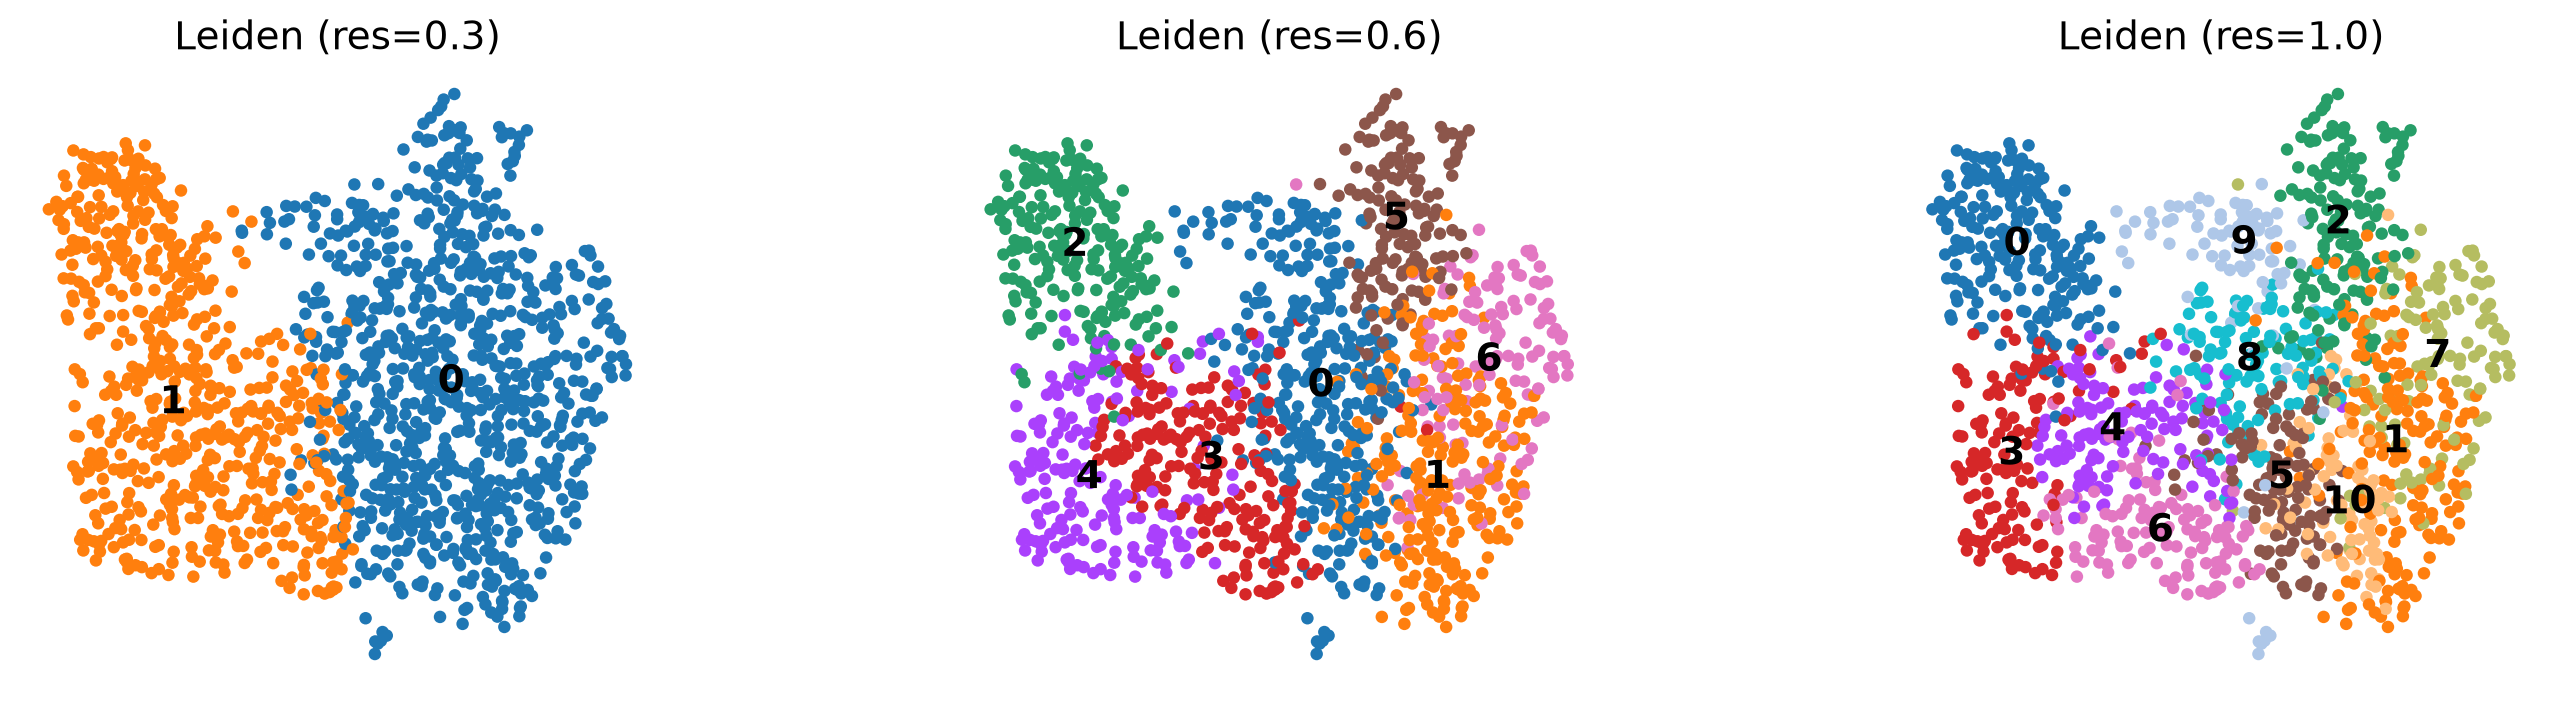

In [8]:
# 2. Графовая кластеризация Leiden при разных значениях разрешения (resolution) и расчёт UMAP
resolutions = [0.3, 0.6, 1.0]
leiden_keys = []

for res in resolutions:
    key = f"leiden_{res}"
    sc.tl.leiden(adata, resolution=res, key_added=key, random_state=42)
    leiden_keys.append(key)
    n_clusters = adata.obs[key].nunique()
    print(f"Leiden (resolution={res}): найдено {n_clusters} кластеров")

# Расчёт нелинейного вложения UMAP для визуализации
sc.tl.umap(adata, random_state=42)

sc.pl.umap(
    adata,
    color=leiden_keys,
    ncols=3,
    wspace=0.35,
    legend_loc="on data",
    title=[f"Leiden (res={r})" for r in resolutions],
    show=True
)

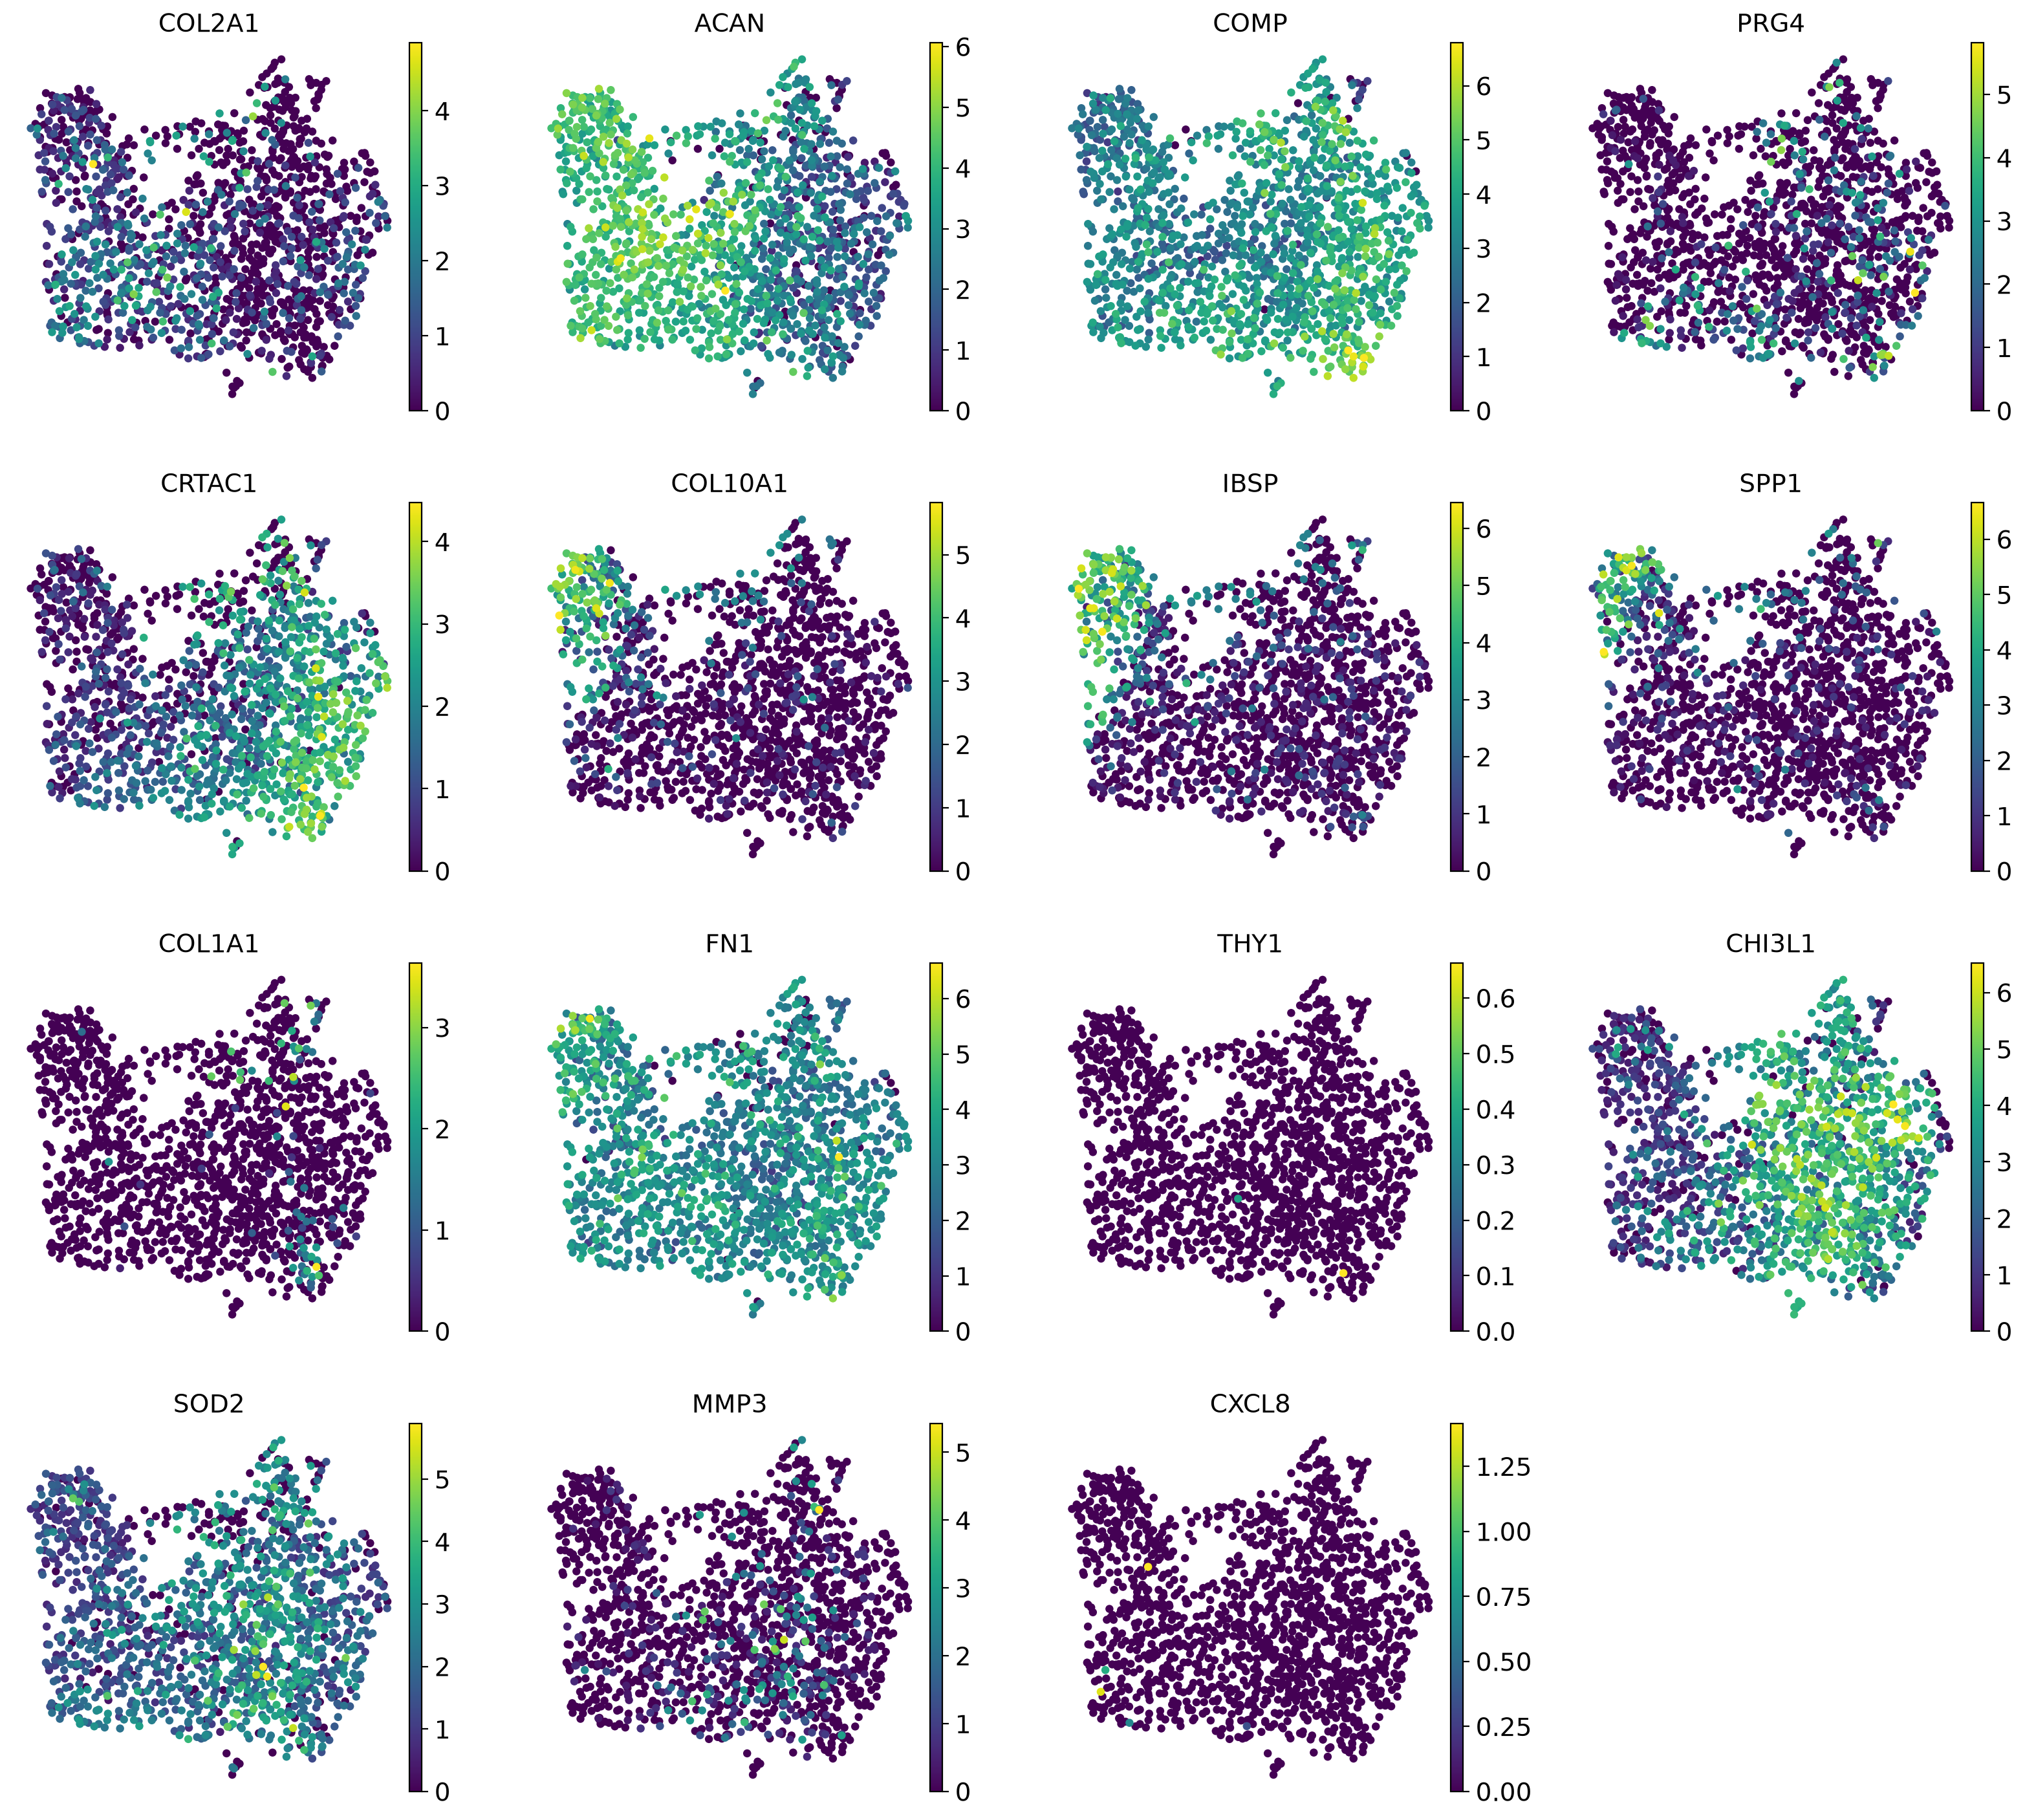

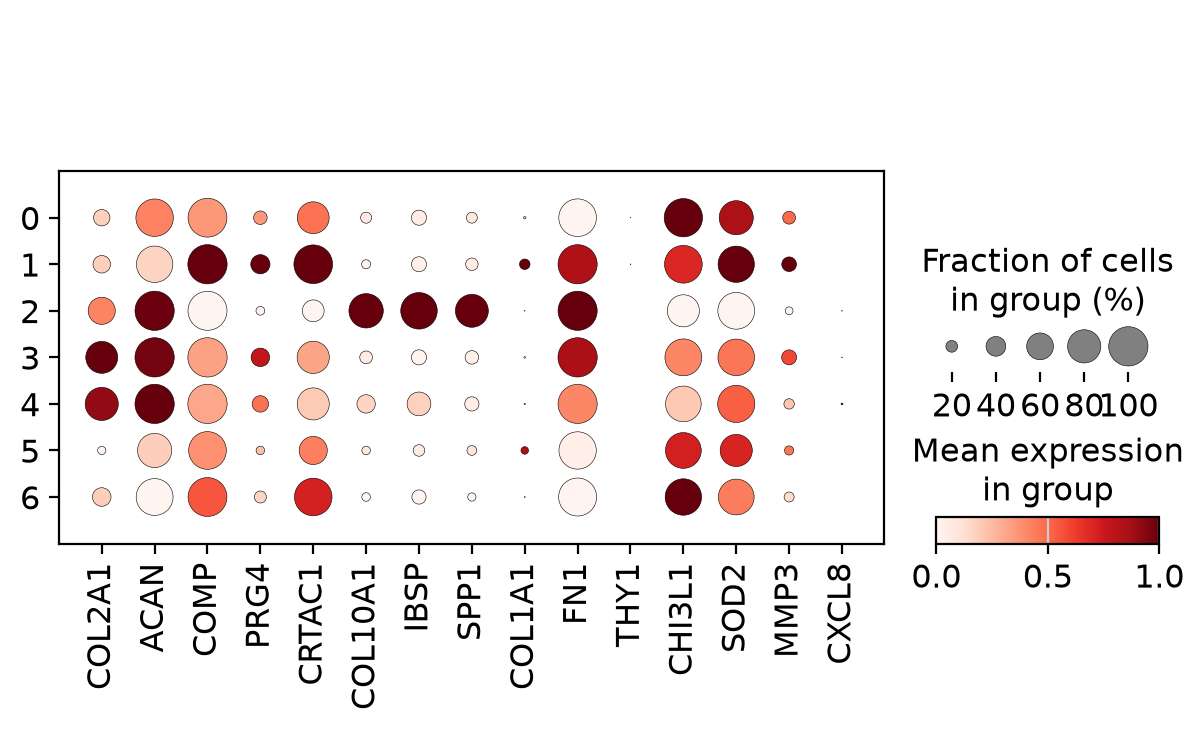

In [9]:
# 3. Окраска UMAP и DotPlot по ключевым маркерам субпопуляций хондроцитов (Fan et al., 2024)
extended_cartilage_panel = [
    g for g in [
        "COL2A1", "ACAN", "COMP",          # Эффекторные / Матриксные (EC)
        "PRG4", "CRTAC1",                  # Поверхностная зона / Гомеостатические (HomC)
        "COL10A1", "IBSP", "SPP1",         # Прегипертрофические / Гипертрофические (preHTC / HTC)
        "COL1A1", "FN1", "THY1",           # Фиброзные хондроциты (FC)
        "CHI3L1", "SOD2", "MMP3", "CXCL8"  # Воспалительные / Регуляторные (InfC / RegC)
    ] if g in adata.var_names
]

sc.pl.umap(adata, color=extended_cartilage_panel, ncols=4, cmap="viridis", show=True)
sc.pl.dotplot(adata, var_names=extended_cartilage_panel, groupby="leiden_0.6", standard_scale="var", show=True)

In [10]:
# Сохранение итогового обработанного объекта AnnData
out_h5ad = DATA_DIR / "gse255460_cartilage_processed.h5ad"
adata.write(out_h5ad)
print(f"Готовый обработанный датасет сохранён в: {out_h5ad}")

Готовый обработанный датасет сохранён в: data_gse255460/gse255460_cartilage_processed.h5ad


### Вывод: Анализ экспрессии канонических маркеров подтверждает наличие в датасете различных функциональных зон хряща: от нормального матрикса (COL2A1) до фиброзного (COL1A1) и прегипертрофического (COL10A1).